In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
hyper = neurons.HyperConfig1(nd=20, ns=3000, n=1, b=2.300, bk=5.75, beta=14.7099)
hyperD = neurons.HyperDynConfig1(b=2.300, bk=5.75, beta=14.7099)
neuron = neurons.Neuron_Decay_Int(hyper)
# neuron = neurons.Neuron_Decay_NonInt(hyper)
# neuron = neurons.Neuron_Decay_Int_NoNonLinearity(hyper)
xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=hyper.nd, ns=hyper.ns, coeff=4, key=jax.random.PRNGKey(42))

# my_driver = driver.Driver1_bScan(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     rng=jax.random.PRNGKey(223313),
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000,
#     n_tested_patterns=1000,
# )

my_driver = driver.Driver1_NoisyRecall_SomaNoise3(
    neuron=neuron,
    xs_generator=xs_gen,
    noise_level=0.3, 
    max_Y=3.0,
    rng=jax.random.PRNGKey(223313),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

# my_driver = driver.Driver1_noNonlinearity(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     rng=jax.random.PRNGKey(333),
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000,
#     n_tested_patterns=1000,
# )

In [3]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([2.3]),
)

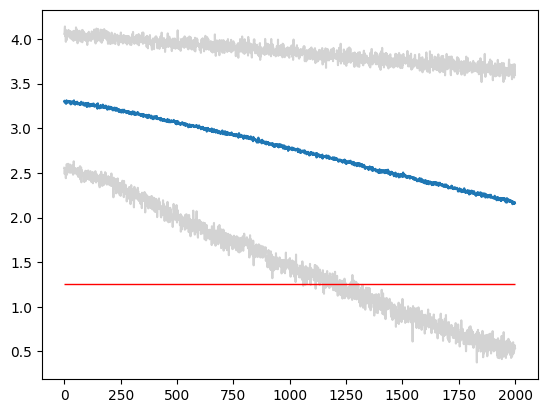

In [4]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

In [6]:
my_driver.upper99_s - steady_upper

Array([0.01174879], dtype=float32)

In [11]:
utils.capacity_numba(my_driver.transient_record, my_driver.steady_record)

array([0.])

(array([2., 2., 5., 2., 2., 1., 1., 3., 1., 1.]),
 array([0.97204673, 0.97841489, 0.98478305, 0.99115127, 0.99751943,
        1.00388765, 1.01025581, 1.01662397, 1.02299213, 1.02936029,
        1.03572845]),
 <BarContainer object of 10 artists>)

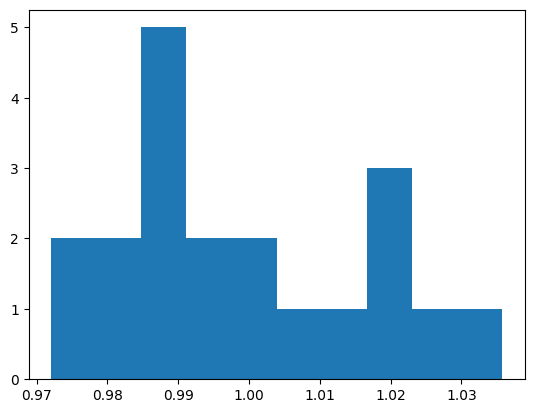

In [16]:
plt.hist(jnp.linalg.norm(my_driver.state.w, axis=-1))

In [10]:
import flax.struct
flax.struct.dataclasses.replace(my_driver.state, rng=jax.random.PRNGKey(0))

State1(w=Array([[-0.00468519,  0.02540464, -0.01757906, ..., -0.01862898,
        -0.00193798,  0.0325911 ],
       [ 0.00535796,  0.03525281,  0.00242752, ..., -0.02250243,
        -0.00199976, -0.03060154],
       [ 0.029612  ,  0.01480129,  0.00090192, ..., -0.02556135,
         0.00408428, -0.01433455],
       ...,
       [ 0.01949144, -0.0001214 , -0.02307326, ..., -0.00869473,
        -0.04127932, -0.01719762],
       [-0.02713487, -0.01355609, -0.0129555 , ...,  0.00830559,
        -0.01398109, -0.01065365],
       [ 0.01292062,  0.00932324,  0.00252905, ...,  0.04404952,
        -0.01464401,  0.02349894]], dtype=float32), rng=Array([0, 0], dtype=uint32))

In [15]:
from flax.struct import dataclass

@dataclass
class State1:
    w: jnp.ndarray # shape (nd, ns)
    rng: jnp.ndarray = 1 # PRNGKey

state = State1(
    w=jnp.zeros((10, 20)),
    rng=jax.random.PRNGKey(0),
)